# Credit Default Risk — Step 3: Explaining Decisions

A score alone is not enough in lending. When an applicant is declined, the lender should be able to say **why**. This notebook uses **SHAP values** to:
1. Rank features by how much they actually move predictions (more reliable than XGBoost's built-in "gain")
2. Check that each feature pushes risk in a sensible direction
3. Produce **reason codes** for any single applicant: the factors that raised or lowered their risk

SHAP splits each prediction into a contribution from every feature, measured in log-odds. Contributions add up exactly to the model's output, so the explanation is faithful to the model, not an approximation of it. XGBoost computes them natively (`pred_contribs=True`), so no extra library is needed.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split

from features import prepare, split_xy

DATA_PATH = Path("data/application_train.csv")
RESULTS = Path("results"); MODELS = Path("models")
RANDOM_STATE = 42

model = xgb.XGBClassifier()
model.load_model(MODELS / "xgb_model.json")
schema = json.loads((MODELS / "schema.json").read_text())
THRESHOLD = schema["threshold"]
print(f"Loaded model. Approval threshold: default probability < {THRESHOLD:.2f}")

Loaded model. Approval threshold: default probability < 0.16


## 1. Rebuild the same test set as Step 2

In [2]:
X, y = split_xy(prepare(pd.read_csv(DATA_PATH)))
_, X_test, _, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_test = X_test[schema["features"]]
print(f"Test applicants: {len(X_test):,}")

Test applicants: 49,202


## 2. Compute SHAP values

In [3]:
booster = model.get_booster()
dtest = xgb.DMatrix(X_test, enable_categorical=True)
contribs = booster.predict(dtest, pred_contribs=True)       # shape: (applicants, features + 1)
shap_vals = pd.DataFrame(contribs[:, :-1], columns=X_test.columns, index=X_test.index)
base_value = float(contribs[0, -1])                          # the model's average log-odds

# Sanity check: base value + contributions = the model's own log-odds output
margin = booster.predict(dtest, output_margin=True)
print("Contributions add up to the model output:", np.allclose(base_value + shap_vals.sum(axis=1), margin, atol=1e-4))
proba = 1 / (1 + np.exp(-margin))
print(f"Average predicted default probability: {proba.mean():.2%}   Actual: {y_test.mean():.2%}")

Contributions add up to the model output: True
Average predicted default probability: 7.96%   Actual: 8.03%


## 3. Global importance

Mean absolute SHAP value: on average, how far each feature moves an applicant's risk. Unlike "gain", this reflects every prediction, not just how trees were split during training.

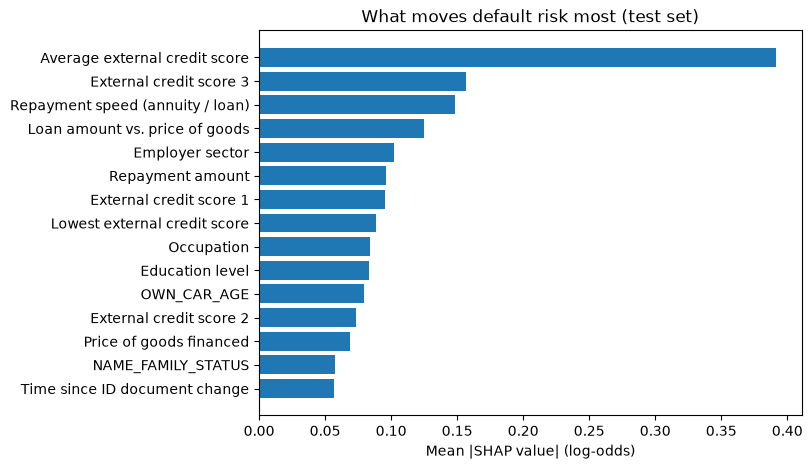

In [4]:
LABELS = {
    "EXT_SOURCE_MEAN": "Average external credit score",
    "EXT_SOURCE_MIN": "Lowest external credit score",
    "EXT_SOURCE_1": "External credit score 1",
    "EXT_SOURCE_2": "External credit score 2",
    "EXT_SOURCE_3": "External credit score 3",
    "CREDIT_TO_GOODS": "Loan amount vs. price of goods",
    "CREDIT_TERM": "Repayment speed (annuity / loan)",
    "ANNUITY_INCOME_RATIO": "Share of income going to repayments",
    "CREDIT_INCOME_RATIO": "Loan size vs. income",
    "EMPLOYED_YEARS": "Years in current job",
    "EMPLOYED_TO_AGE": "Share of life in current job",
    "DAYS_EMPLOYED": "Time in current job",
    "AGE_YEARS": "Age",
    "DAYS_BIRTH": "Age",
    "NAME_EDUCATION_TYPE": "Education level",
    "NAME_CONTRACT_TYPE": "Loan type",
    "ORGANIZATION_TYPE": "Employer sector",
    "OCCUPATION_TYPE": "Occupation",
    "AMT_GOODS_PRICE": "Price of goods financed",
    "AMT_CREDIT": "Loan amount",
    "AMT_ANNUITY": "Repayment amount",
    "FLAG_DOCUMENT_3": "Document 3 provided",
    "DEF_30_CNT_SOCIAL_CIRCLE": "Defaults in social circle (30 days)",
    "DEF_60_CNT_SOCIAL_CIRCLE": "Defaults in social circle (60 days)",
    "AMT_REQ_CREDIT_BUREAU_DAY": "Credit checks in the last day",
    "DAYS_ID_PUBLISH": "Time since ID document change",
    "DAYS_LAST_PHONE_CHANGE": "Time since phone change",
    "REGION_RATING_CLIENT_W_CITY": "Region rating",
    "FLAG_OWN_CAR": "Owns a car",
}
label = lambda f: LABELS.get(f, f)

mean_abs = shap_vals.abs().mean().sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh([label(f) for f in mean_abs.index[::-1]], mean_abs.values[::-1])
ax.set_xlabel("Mean |SHAP value| (log-odds)"); ax.set_title("What moves default risk most (test set)")
fig.savefig(RESULTS / "shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Direction check

For each top numeric feature: does a higher value raise or lower risk? These should match common sense, or the model is learning something odd.

In [5]:
rows = []
for f in mean_abs.index:
    if pd.api.types.is_numeric_dtype(X_test[f]):
        ok = X_test[f].notna()
        corr = np.corrcoef(X_test.loc[ok, f], shap_vals.loc[ok, f])[0, 1]
        rows.append({"feature": label(f), "higher value →": "raises risk" if corr > 0 else "lowers risk", "strength": round(abs(corr), 2)})
pd.DataFrame(rows)

,feature,higher value →,strength
0,Average external credit score,lowers risk,0.98
1,External credit score 3,lowers risk,0.95
2,Repayment speed (annuity / loan),lowers risk,0.20
3,Loan amount vs. price of goods,raises risk,0.90
4,Repayment amount,raises risk,0.74
5,External credit score 1,lowers risk,0.81
6,Lowest external credit score,lowers risk,0.71
7,OWN_CAR_AGE,raises risk,0.75
8,External credit score 2,lowers risk,0.72
9,Price of goods financed,lowers risk,0.67


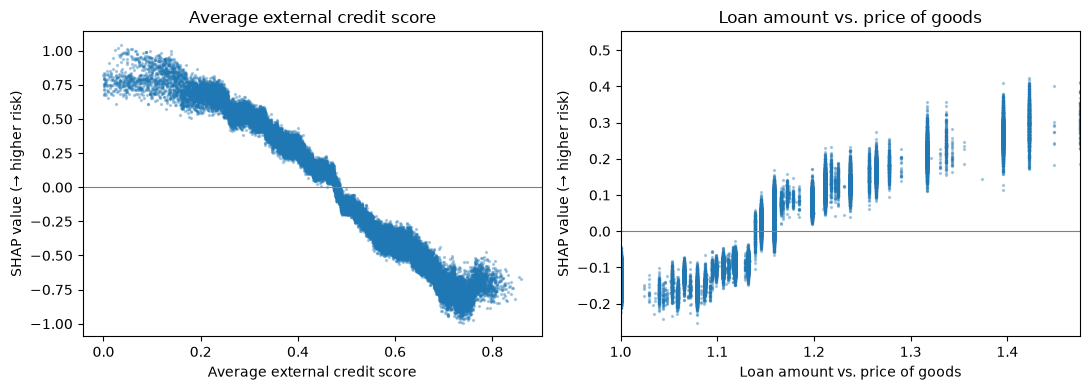

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, f in zip(axes, ["EXT_SOURCE_MEAN", "CREDIT_TO_GOODS"]):
    ok = X_test[f].notna()
    ax.scatter(X_test.loc[ok, f], shap_vals.loc[ok, f], s=2, alpha=0.3)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel(label(f)); ax.set_ylabel("SHAP value (→ higher risk)")
    ax.set_title(label(f))
if X_test["CREDIT_TO_GOODS"].notna().any():
    axes[1].set_xlim(*X_test["CREDIT_TO_GOODS"].quantile([0.01, 0.99]))
fig.tight_layout()
fig.savefig(RESULTS / "shap_dependence.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Reason codes for individual applicants

For one applicant: their predicted default probability, the decision, and the factors that pushed their risk up or down the most.

Applicant 6235: default probability 76.0% → DECLINE  (actual outcome: defaulted)
  Raised risk:
    + Average external credit score = 0.11  (+0.90)
    + External credit score 3 = 0.04  (+0.63)
    + Lowest external credit score = 0.04  (+0.47)
    + Repayment speed (annuity / loan) = 0.07  (+0.38)
  Lowered risk:
    − WEEKDAY_APPR_PROCESS_START = SUNDAY  (-0.05)
    − NAME_INCOME_TYPE = Commercial associate  (-0.04)
    − Employer sector = Business Entity Type 1  (-0.03)
    − NAME_FAMILY_STATUS = Married  (-0.02)


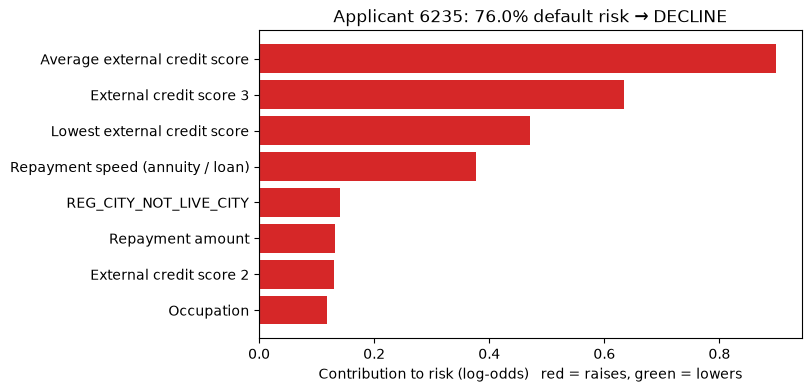

In [7]:
def explain(idx, top=4):
    s = shap_vals.loc[idx]
    p = float(proba[X_test.index.get_loc(idx)])
    decision = "APPROVE" if p < THRESHOLD else "DECLINE"
    up = s[s > 0].sort_values(ascending=False).head(top)
    down = s[s < 0].sort_values().head(top)
    def fmt(f, v):
        if pd.isna(v):
            return "missing"
        if f.startswith("DAYS_"):                      # stored as negative days before application
            return f"{abs(v) / 365.25:.1f} years"
        if isinstance(v, (int, float, np.integer, np.floating)):
            return f"{v:,.2f}"
        return str(v)
    print(f"Applicant {idx}: default probability {p:.1%} → {decision}  (actual outcome: {'defaulted' if y_test.loc[idx] else 'repaid'})")
    print("  Raised risk:")
    for f, v in up.items():
        print(f"    + {label(f)} = {fmt(f, X_test.loc[idx, f])}  ({v:+.2f})")
    print("  Lowered risk:")
    for f, v in down.items():
        print(f"    − {label(f)} = {fmt(f, X_test.loc[idx, f])}  ({v:+.2f})")
    return s, p, decision

def plot_explanation(idx, s, p, decision, top=8):
    s = s.reindex(s.abs().sort_values(ascending=False).index).head(top)[::-1]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.barh([label(f) for f in s.index], s.values, color=["#d62728" if v > 0 else "#2ca02c" for v in s.values])
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_xlabel("Contribution to risk (log-odds)   red = raises, green = lowers")
    ax.set_title(f"Applicant {idx}: {p:.1%} default risk → {decision}")
    return fig

# One declined and one approved applicant from the test set
declined_idx = X_test.index[np.argmax(proba)] if (proba >= THRESHOLD).any() else X_test.index[0]
approved_idx = X_test.index[np.argmin(proba)]

s, p, d = explain(declined_idx)
plot_explanation(declined_idx, s, p, d).savefig(RESULTS / "reason_codes_declined.png", dpi=150, bbox_inches="tight")
plt.show()

Applicant 190843: default probability 0.2% → APPROVE  (actual outcome: repaid)
  Raised risk:
    + Repayment speed (annuity / loan) = 0.05  (+0.04)
    + Repayment amount = 33,750.00  (+0.04)
    + FLAG_CONT_MOBILE = 0.00  (+0.04)
    + AMT_INCOME_TOTAL = 450,000.00  (+0.03)
  Lowered risk:
    − Average external credit score = 0.67  (-0.66)
    − External credit score 2 = 0.78  (-0.48)
    − Employer sector = Hotel  (-0.36)
    − OWN_CAR_AGE = 3.00  (-0.27)


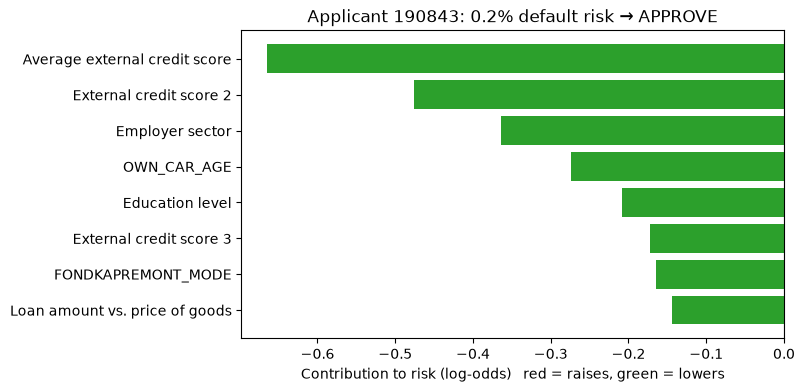

In [8]:
s, p, d = explain(approved_idx)
plot_explanation(approved_idx, s, p, d).savefig(RESULTS / "reason_codes_approved.png", dpi=150, bbox_inches="tight")
plt.show()

**Try it yourself:** pick any applicant, e.g. a borderline one near the threshold:

In [9]:
borderline_idx = X_test.index[np.argmin(np.abs(proba - THRESHOLD))]
_ = explain(borderline_idx)

Applicant 207999: default probability 16.0% → DECLINE  (actual outcome: defaulted)
  Raised risk:
    + Repayment speed (annuity / loan) = 0.08  (+0.44)
    + Average external credit score = 0.41  (+0.19)
    + Employer sector = Self-employed  (+0.12)
    + Repayment amount = 37,462.50  (+0.09)
  Lowered risk:
    − Occupation = Accountants  (-0.28)
    − Time since ID document change = 15.9 years  (-0.19)
    − Loan amount vs. price of goods = 1.00  (-0.15)
    − FLAG_WORK_PHONE = 0.00  (-0.04)


In [10]:
summary = {
    "top_features_by_mean_abs_shap": [label(f) for f in mean_abs.index[:10]],
    "shap_sums_match_model": bool(np.allclose(base_value + shap_vals.sum(axis=1), margin, atol=1e-4)),
}
(RESULTS / "shap_summary.json").write_text(json.dumps(summary, indent=2))
summary

{'top_features_by_mean_abs_shap': ['Average external credit score',
  'External credit score 3',
  'Repayment speed (annuity / loan)',
  'Loan amount vs. price of goods',
  'Employer sector',
  'Repayment amount',
  'External credit score 1',
  'Lowest external credit score',
  'Occupation',
  'Education level'],
 'shap_sums_match_model': True}

## Next step
Send back the **importance chart**, the **direction table** and the **declined applicant's reason codes**. Step 4 wraps the model and these reason codes in an API and deploys it on AWS.